# Review a labeled dataset image

Select an image number to see the original image, the semantic labels overlaid in color, and tobacco detection boxes. These labels are automatically generated and are not independent ground truth. This notebook only reads the dataset; it does not change labels or create outputs.


In [2]:
from pathlib import Path
import json

ROOT = Path('../')


In [3]:
RUN_REVIEW = True
# DATASET = ROOT / 'experiments/reproductions/tobacco-pseudolabels-05'
DATASET = ROOT / 'data/tobacco_migrated'
IMAGE_NUMBER = 1


## Load an image and its labels

Image number `1` selects `image_000001.png`. Masks use 0 for background, 1 for tobacco, and 2 for weed. The box file contains normalized YOLO detection coordinates for tobacco only. An empty box file means no tobacco detections were saved.


In [4]:
def read_example(dataset, image_number):
    import numpy as np
    from PIL import Image
    dataset = Path(dataset)
    if type(image_number) is not int or image_number < 1:
        raise ValueError('IMAGE_NUMBER must be a positive integer.')
    summary = json.loads((dataset / 'summary.json').read_text(encoding='utf-8'))
    if summary.get('status') != 'complete':
        raise ValueError('The selected dataset run is not complete.')
    name = f'image_{image_number:06d}'
    image_path = dataset / 'images' / f'{name}.png'
    mask_path = dataset / 'semantic_masks' / f'{name}.png'
    box_path = dataset / 'labels' / f'{name}.txt'
    for path in (image_path, mask_path, box_path):
        if not path.is_file():
            raise FileNotFoundError(f'Missing image or label for {name}: {path}')
    with Image.open(image_path) as source:
        image = np.asarray(source.convert('RGB'))
    with Image.open(mask_path) as source:
        mask = np.asarray(source)
    if mask.shape != image.shape[:2] or not np.isin(mask, [0, 1, 2]).all():
        raise ValueError(f'Invalid semantic mask for {name}: {mask_path}')
    boxes = []
    for line_number, line in enumerate(box_path.read_text(encoding='utf-8').splitlines(), 1):
        fields = line.split()
        if len(fields) != 5 or fields[0] != '0':
            raise ValueError(f'Invalid tobacco box at {box_path}:{line_number}')
        try:
            center_x, center_y, width, height = (float(value) for value in fields[1:])
        except ValueError as error:
            raise ValueError(f'Invalid box coordinates at {box_path}:{line_number}') from error
        values = np.array([center_x, center_y, width, height])
        if (not np.isfinite(values).all() or width <= 0 or height <= 0
                or center_x - width / 2 < -1e-6 or center_y - height / 2 < -1e-6
                or center_x + width / 2 > 1 + 1e-6 or center_y + height / 2 > 1 + 1e-6):
            raise ValueError(f'Out-of-bounds box at {box_path}:{line_number}')
        boxes.append((center_x, center_y, width, height))
    return image, mask, boxes


def plot_example(image, mask, boxes, image_number):
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch, Rectangle
    overlay = np.zeros((*mask.shape, 4), dtype=float)
    overlay[mask == 1] = (1.0, 0.2, 0.2, 0.55)
    overlay[mask == 2] = (0.1, 0.9, 0.2, 0.55)
    figure, axes = plt.subplots(1, 3, figsize=(18, 6))
    for axis in axes:
        axis.imshow(image)
        axis.axis('off')
    axes[0].set_title(f'Original: image_{image_number:06d}')
    axes[1].imshow(overlay)
    axes[1].set_title('Semantic labels')
    axes[1].legend(handles=[Patch(color=(1.0, 0.2, 0.2), label='Tobacco'),
                            Patch(color=(0.1, 0.9, 0.2), label='Weed')], loc='lower right')
    height, width = mask.shape
    for center_x, center_y, box_width, box_height in boxes:
        axes[2].add_patch(Rectangle(((center_x - box_width / 2) * width,
                                     (center_y - box_height / 2) * height),
                                    box_width * width, box_height * height,
                                    fill=False, edgecolor='yellow', linewidth=2))
    axes[2].set_title(f'Tobacco boxes: {len(boxes)}')
    figure.tight_layout()
    return figure


## Display

Set `RUN_REVIEW = True` and choose `IMAGE_NUMBER`, then run all cells. To review another image, change the number and rerun the configuration and display cells.


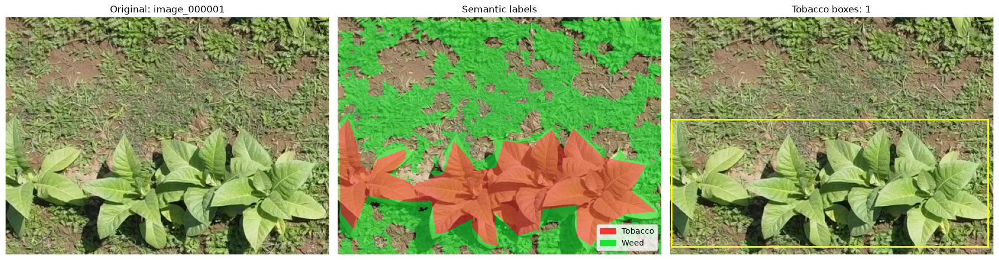

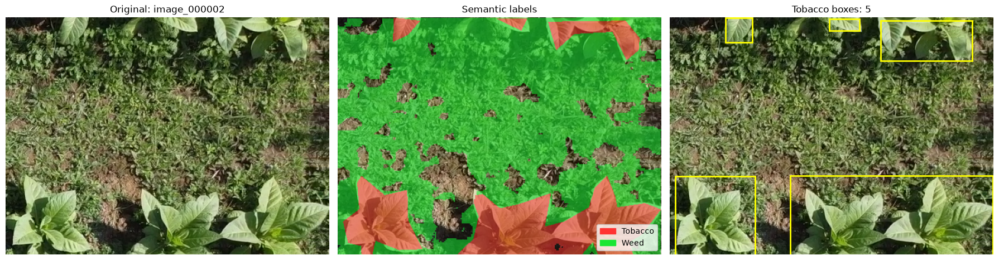

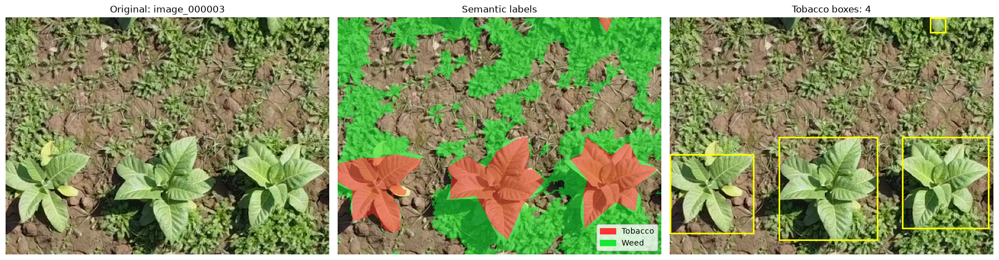

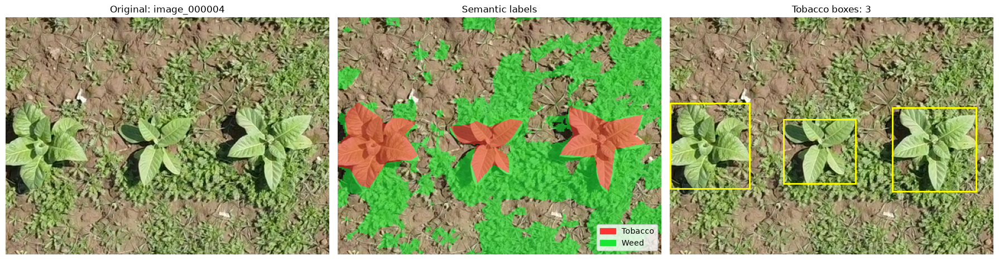

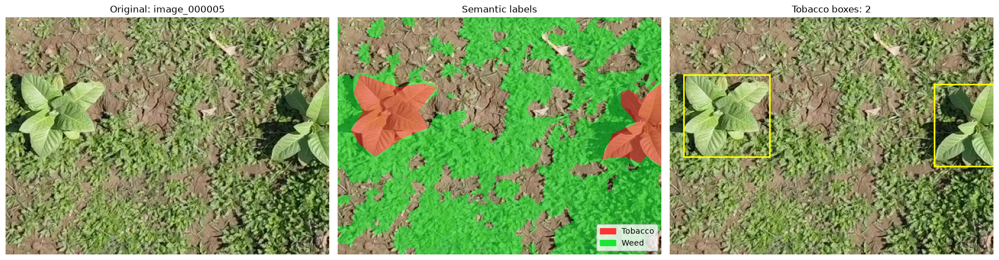

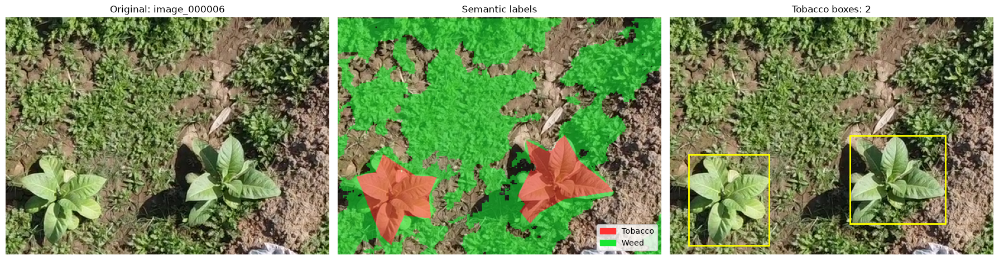

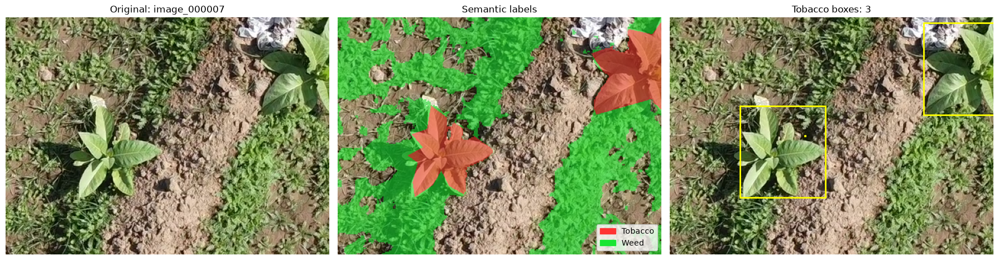

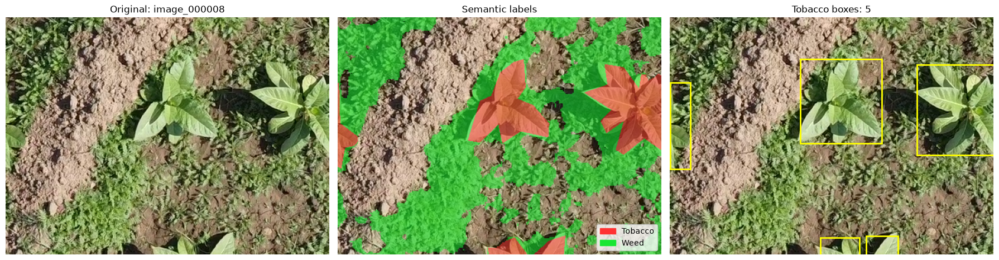

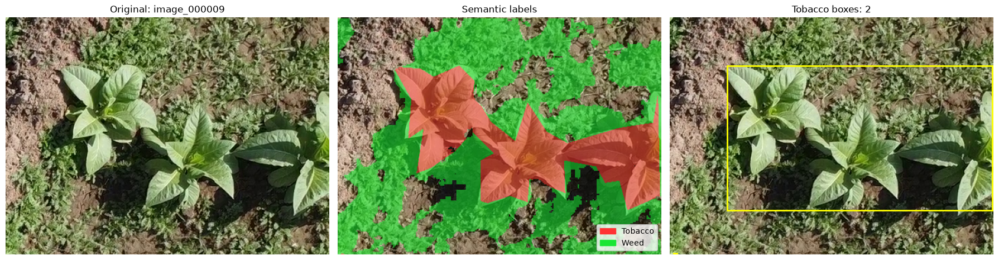

In [5]:
if RUN_REVIEW:
    import matplotlib.pyplot as plt
    for i in range(1, 10): 
        IMAGE_NUMBER = i
        image, mask, boxes = read_example(DATASET, IMAGE_NUMBER)
        figure = plot_example(image, mask, boxes, IMAGE_NUMBER)
        plt.show()
else:
    print('Review disabled. Set RUN_REVIEW=True and choose IMAGE_NUMBER.')
